In [64]:
import pandas as pd

df = pd.read_csv('data/house_prices.csv')

In [65]:
df.head()

,Area,Bedrooms,Bathrooms,Floors,Age,Price
0,800,2,1,1,10,3500000
1,900,2,2,1,8,4000000
2,1000,2,2,1,5,4500000
3,1100,2,2,2,7,4800000
4,1200,3,2,1,6,5200000


In [66]:
df.shape

(105, 6)

In [67]:
df.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Area       105 non-null    int64
 1   Bedrooms   105 non-null    int64
 2   Bathrooms  105 non-null    int64
 3   Floors     105 non-null    int64
 4   Age        105 non-null    int64
 5   Price      105 non-null    int64
dtypes: int64(6)
memory usage: 5.1 KB


In [68]:
df.describe()

,Area,Bedrooms,Bathrooms,Floors,Age,Price
count,105.00000,105.000000,105.000000,105.000000,105.000000,1.050000e+02
mean,1929.52381,3.495238,2.847619,1.895238,7.190476,8.273333e+06
std,1907.54997,1.161264,1.007481,0.649316,7.930098,5.403885e+06
min,300.00000,1.000000,1.000000,1.000000,0.000000,5.000000e+05
25%,1220.00000,3.000000,2.000000,1.000000,2.000000,5.200000e+06
50%,1750.00000,3.000000,3.000000,2.000000,5.000000,7.500000e+06
75%,2280.00000,4.000000,4.000000,2.000000,9.000000,1.030000e+07
max,20000.00000,8.000000,6.000000,4.000000,50.000000,5.000000e+07


In [69]:
print(df.isnull().sum())

Area         0
Bedrooms     0
Bathrooms    0
Floors       0
Age          0
Price        0
dtype: int64


array([[<Axes: title={'center': 'Area'}>,
        <Axes: title={'center': 'Bedrooms'}>],
       [<Axes: title={'center': 'Bathrooms'}>,
        <Axes: title={'center': 'Floors'}>],
       [<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Price'}>]], dtype=object)

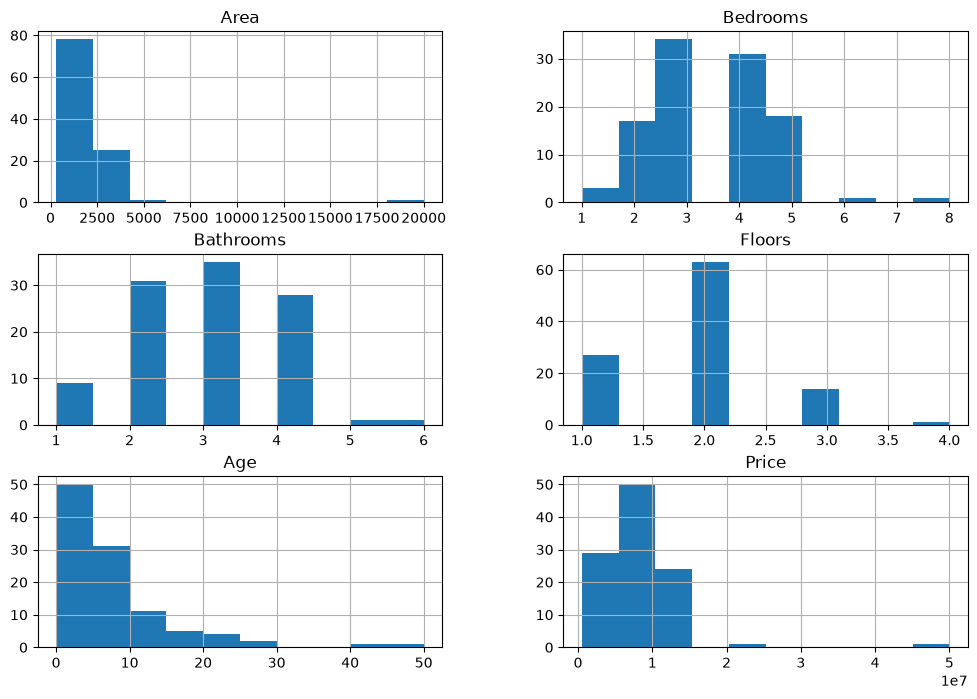

In [70]:
import seaborn as sns 
import matplotlib.pyplot as plt

df.hist(figsize=(12,8),bins=10)


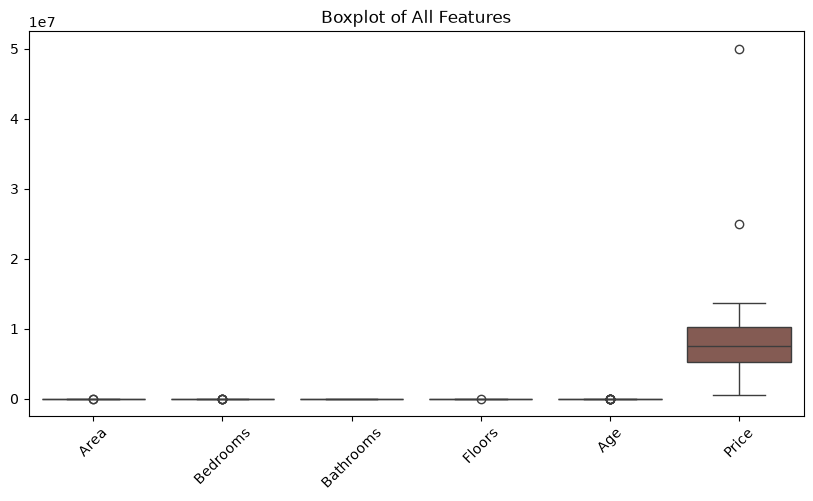

In [71]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df)
plt.xticks(rotation=45)
plt.title("Boxplot of All Features")
plt.show()

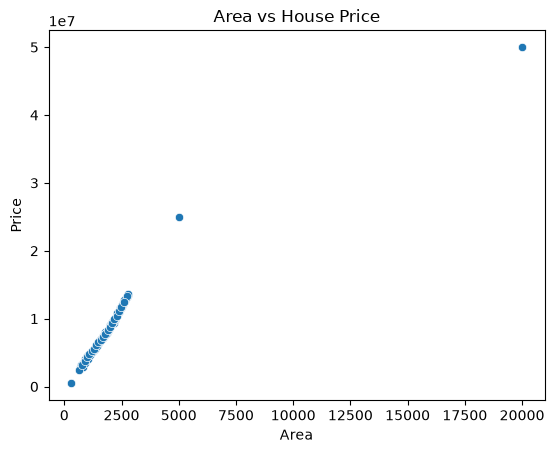

In [72]:
sns.scatterplot(data=df, x="Area", y="Price")
plt.title("Area vs House Price")
plt.show()

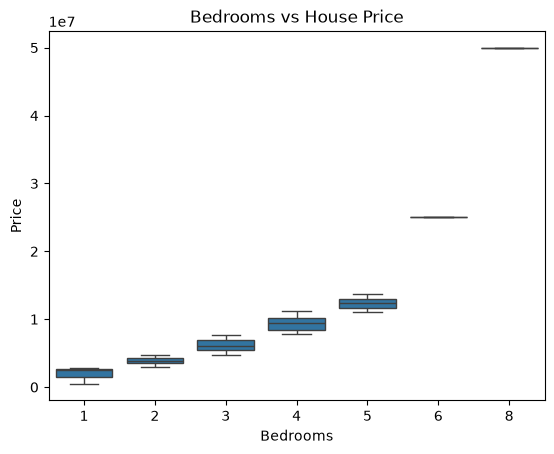

In [73]:
sns.boxplot(data=df, x="Bedrooms", y="Price")
plt.title("Bedrooms vs House Price")
plt.show()

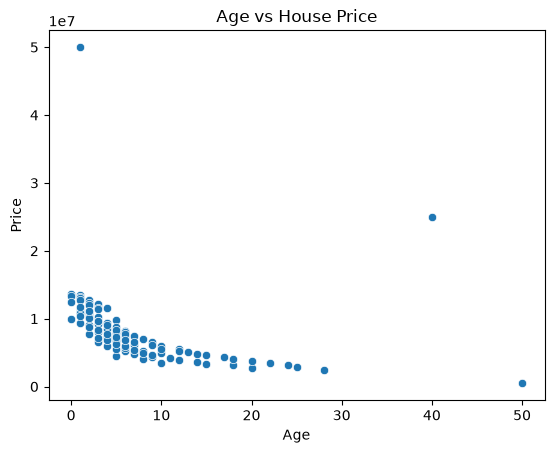

In [74]:
sns.scatterplot(data=df, x="Age", y="Price")
plt.title("Age vs House Price")
plt.show()

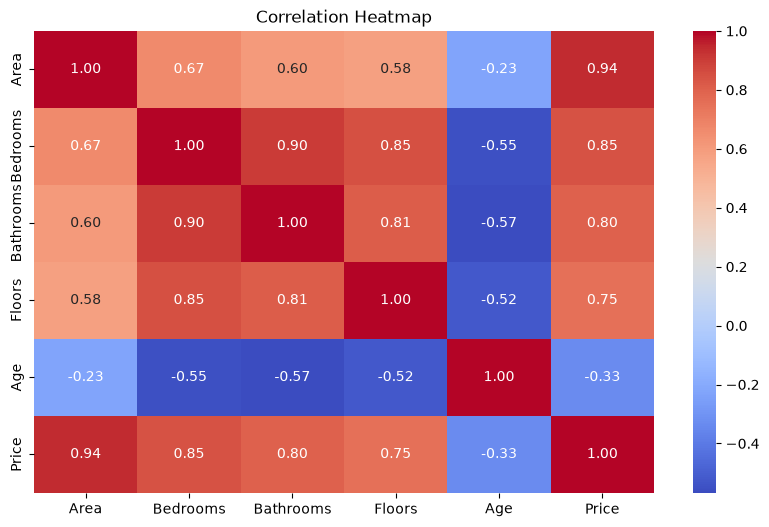

In [75]:
correlation = df.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [76]:
df

,Area,Bedrooms,Bathrooms,Floors,Age,Price
0,800,2,1,1,10,3500000
1,900,2,2,1,8,4000000
2,1000,2,2,1,5,4500000
3,1100,2,2,2,7,4800000
4,1200,3,2,1,6,5200000
...,...,...,...,...,...,...
100,2490,5,4,3,1,11700000
101,2590,5,4,3,0,12400000
102,20000,8,6,4,1,50000000
103,300,1,1,1,50,500000


In [77]:
from sklearn.model_selection import train_test_split

x = df[['Area','Bedrooms','Bathrooms','Floors']]
y= df['Price']

xtrain,xtest,ytrain,ytest = train_test_split(x,y,train_size=0.7)

In [78]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(xtrain,ytrain)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 1918.52,839786.97,986518.31,482304.86]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Area','Bedrooms','Bathrooms','Floors']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.066e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [79]:
ypred=model.predict(xtest)
ypred

array([12610278.55608042, 12495167.11606521,  3776669.06516818,
       12514352.35606775,  7447431.24544249,  7293949.32542221,
        7543357.44545516,  7639283.64546783,  3987706.70519605,
        9150554.01583399,  8958701.61580864,  6058022.89772793,
        9246480.21584665,  5866170.49770259,  8709293.4957757 ,
       12552722.83607282,  9035442.57581878,  5192013.23552167,
        9054627.81582131,  2770965.5175043 ,  6269060.5377558 ,
        4026077.18520112,  3834224.78517578, 12667834.27608802,
         818434.62707986,  3949336.22519098,  7735209.8454805 ,
        6173134.33774313,  5403050.87554954, 10578332.84355361,
        9342406.41585932, 11840195.09388683])

In [83]:
result = pd.DataFrame({
    "Actual Values": ytest.values,
    "Predicted Values": ypred.round()
})

result.head(10)

,Actual Values,Predicted Values
0,12800000,12610279.0
1,12400000,12495167.0
2,3700000,3776669.0
3,12500000,12514352.0
4,7000000,7447431.0
5,6500000,7293949.0
6,7100000,7543357.0
7,7400000,7639284.0
8,4500000,3987707.0
9,9200000,9150554.0


In [84]:
from sklearn.metrics import r2_score , mean_absolute_error ,mean_squared_error

print("r2_score",r2_score(y_pred=ypred,y_true=ytest))
print("Mean Absolute Error",mean_absolute_error(y_pred=ypred,y_true=ytest))
print("Mean Squared Error",mean_squared_error(y_pred=ypred,y_true=ytest))

r2_score 0.9877435856046047
Mean Absolute Error 262108.38242209185
Mean Squared Error 123109817715.95097
